# TP1 Comptage de mots - OZEL IBRAHIM
### Python simple vs Pseudo-MapReduce vs Hadoop MapReduce

**Objectif :** compter les occurrences de chaque mot d'un fichier avec trois méthodes, puis comparer leurs temps d'exécution sur des fichiers de plus en plus gros.

In [1]:
import os, time, random
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

## 1. Génération des fichiers

- Un fichier de base de **N lignes**, un mot par ligne (tirés au hasard, donc avec répétition).
- Des fichiers de **m × N lignes**, obtenus en dupliquant les N lignes **m fois**.

In [2]:
N = 500
M_VALEURS = [1, 5, 50, 50000]   # de 500 à 25 000 000 lignes
VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne",
               "livre", "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]

random.seed(42)
base = random.choices(VOCABULAIRE, k=N)       # N lignes, un mot par ligne

FICHIERS = {}
for m in M_VALEURS:
    FICHIERS[m] = f"mots_m{m}.txt"
    with open(FICHIERS[m], "w", encoding="utf-8", newline="\n") as f:
        f.write(("\n".join(base) + "\n") * m)   # duplication m fois

for m, fichier in FICHIERS.items():
    print(f"{fichier:16s} : {m * N:9d} lignes, {os.path.getsize(fichier) / 1e6:7.1f} Mo")

mots_m1.txt      :       500 lignes,     0.0 Mo
mots_m5.txt      :      2500 lignes,     0.0 Mo
mots_m50.txt     :     25000 lignes,     0.2 Mo
mots_m50000.txt  :  25000000 lignes,   157.4 Mo


Chaque méthode est exécutée **une fois** sur chaque fichier et on mesure son temps d'exécution.

In [3]:
def mesurer(fonction, fichier):
    debut = time.perf_counter()
    resultat = fonction(fichier)
    return resultat, time.perf_counter() - debut

## 2. Méthode 1 : Python simple

Lecture du fichier, découpage en mots, comptage dans un dictionnaire.

In [4]:
def compter_occurrences(fichier):
    with open(fichier, encoding="utf-8") as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

resultats_v1, temps_v1 = {}, {}
for m, fichier in FICHIERS.items():
    resultats_v1[m], temps_v1[m] = mesurer(compter_occurrences, fichier)
    print(f"{m * N:9d} lignes : {temps_v1[m]:.5f} s")

      500 lignes : 0.03762 s
     2500 lignes : 0.02750 s
    25000 lignes : 0.06948 s
 25000000 lignes : 9.64347 s


In [5]:
# Test : résultat sur le fichier de base
sorted(resultats_v1[1].items(), key=lambda x: -x[1])

[('fleur', 52),
 ('montagne', 38),
 ('maison', 37),
 ('chien', 37),
 ('ciel', 37),
 ('oiseau', 37),
 ('voiture', 36),
 ('mer', 35),
 ('jardin', 34),
 ('lune', 32),
 ('chat', 28),
 ('route', 28),
 ('livre', 24),
 ('arbre', 24),
 ('soleil', 21)]

## 3. Méthode 2 : Pseudo-MapReduce (Python)

Les trois étapes de MapReduce, exécutées sur une seule machine :
- **map** : chaque ligne → paires `(mot, 1)`
- **shuffle** : regroupement des valeurs par mot
- **reduce** : somme des valeurs de chaque mot

In [6]:
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

def pseudo_mapreduce(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    grouped = shuffle(mapped)
    reduced = reducer(grouped)
    return reduced

resultats_v2, temps_v2 = {}, {}
for m, fichier in FICHIERS.items():
    resultats_v2[m], temps_v2[m] = mesurer(pseudo_mapreduce, fichier)
    print(f"{m * N:9d} lignes : {temps_v2[m]:.5f} s")

      500 lignes : 0.01082 s
     2500 lignes : 0.00409 s
    25000 lignes : 0.04191 s
 25000000 lignes : 32.67978 s


In [7]:
# Test : résultat sur le fichier de base
for mot, count in sorted(resultats_v2[1].items(), key=lambda x: x[1], reverse=True):
    print(f"{mot} : {count}")

fleur : 52
montagne : 38
maison : 37
chien : 37
ciel : 37
oiseau : 37
voiture : 36
mer : 35
jardin : 34
lune : 32
chat : 28
route : 28
livre : 24
arbre : 24
soleil : 21


In [8]:
# Test : les deux méthodes donnent le même résultat
for m in M_VALEURS:
    print(f"{m * N:9d} lignes | total = {sum(resultats_v1[m].values()):9d} | V1 == V2 : {resultats_v1[m] == resultats_v2[m]}")

      500 lignes | total =       500 | V1 == V2 : True
     2500 lignes | total =      2500 | V1 == V2 : True
    25000 lignes | total =     25000 | V1 == V2 : True
 25000000 lignes | total =  25000000 | V1 == V2 : True


## 4. Méthode 3 : Hadoop MapReduce (commandes terminal)

Les cellules suivantes sont des commandes **bash** (`%%bash`), identiques à celles tapées dans un terminal.

**Installation** (une seule fois) :
```bash
sudo pacman -S jdk-openjdk
wget https://dlcdn.apache.org/hadoop/common/hadoop-3.4.0/hadoop-3.4.0.tar.gz
tar -xzf hadoop-3.4.0.tar.gz && mv hadoop-3.4.0 ~/hadoop
echo 'export HADOOP_HOME=$HOME/hadoop' >> ~/.bashrc
echo 'export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin' >> ~/.bashrc
source ~/.bashrc
```


### 4.1 Démarrage de HDFS et YARN
Chaque service est lancé avec `--daemon start` (contrairement à `start-dfs.sh`, cela ne demande pas de SSH).
`jps` doit afficher `NameNode`, `DataNode`, `ResourceManager` et `NodeManager`.

In [14]:
%%bash
export HADOOP_HOME=${HADOOP_HOME:-$HOME/hadoop}
export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin

# Hdfs fonctionne très bien
hdfs getconf -confKey fs.defaultFS

hdfs --daemon start namenode
hdfs --daemon start datanode
yarn --daemon start resourcemanager
yarn --daemon start nodemanager
sleep 5
jps

hdfs://localhost:9000


namenode is running as process 14935.  Stop it first and ensure /tmp/hadoop-zelo-namenode.pid file is empty before retry.
datanode is running as process 15013.  Stop it first and ensure /tmp/hadoop-zelo-datanode.pid file is empty before retry.
resourcemanager is running as process 15098.  Stop it first and ensure /tmp/hadoop-zelo-resourcemanager.pid file is empty before retry.
nodemanager is running as process 15226.  Stop it first and ensure /tmp/hadoop-zelo-nodemanager.pid file is empty before retry.


54884 Jps
15013 DataNode
14935 NameNode
15226 NodeManager
15098 ResourceManager


### 4.2 Envoi des fichiers dans HDFS et lancement des jobs `wordcount`
Pour chaque fichier : copie dans HDFS, suppression de l'ancien dossier de sortie (Hadoop refuse d'écraser), lancement du job et mesure de sa durée. Les temps sont enregistrés dans `temps_hadoop.csv`.

L'option `split.maxsize` (16 Mo) découpe les gros fichiers en plusieurs *splits* : Hadoop lance alors **plusieurs mappers en parallèle** (sur 25 M lignes ≈ 157 Mo, 10 mappers) au lieu d'un seul.

In [10]:
%%bash
export HADOOP_HOME=${HADOOP_HOME:-$HOME/hadoop}
export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin
JAR=$(ls $HADOOP_HOME/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar)
BASE=/user/$USER/wordcount

echo "m,secondes" > temps_hadoop.csv
for m in 1 5 50 50000; do
    hdfs dfs -mkdir -p $BASE/input_m$m
    hdfs dfs -put -f mots_m$m.txt $BASE/input_m$m/
    hdfs dfs -rm -r -f -skipTrash $BASE/output_m$m > /dev/null

    debut=$(date +%s.%N)
    if ! hadoop jar $JAR wordcount -D mapreduce.input.fileinputformat.split.maxsize=16777216 \
           $BASE/input_m$m $BASE/output_m$m 2> hadoop_m$m.log; then
        echo "m=$m : ÉCHEC du job (voir hadoop_m$m.log)"
        continue
    fi
    fin=$(date +%s.%N)

    duree=$(awk "BEGIN {printf \"%.2f\", $fin - $debut}")
    echo "$m,$duree" >> temps_hadoop.csv
    echo "m=$m ($((m * 500)) lignes) : $duree s"
done

m=1 (500 lignes) : 23.81 s
m=5 (2500 lignes) : 21.14 s
m=50 (25000 lignes) : 27.26 s
m=50000 (25000000 lignes) : 47.13 s


### 4.3 Test : résultat de Hadoop et comparaison avec un comptage local
`sort | uniq -c` compte les mots localement ; `diff` ne doit rien afficher si les résultats sont identiques.

In [11]:
%%bash
export HADOOP_HOME=${HADOOP_HOME:-$HOME/hadoop}
export PATH=$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin
BASE=/user/$USER/wordcount

hdfs dfs -cat $BASE/output_m1/part-r-00000

for m in 1 5 50 50000; do
    if diff <(LC_ALL=C sort mots_m$m.txt | uniq -c | awk '{print $2"\t"$1}') \
            <(hdfs dfs -cat $BASE/output_m$m/part-r-00000) > /dev/null; then
        echo "m=$m : résultats Hadoop identiques au comptage local"
    else
        echo "m=$m : DIFFÉRENCE"
    fi
done

arbre	24
chat	28
chien	37
ciel	37
fleur	52
jardin	34
livre	24
lune	32
maison	37
mer	35
montagne	38
oiseau	37
route	28
soleil	21
voiture	36
m=1 : résultats Hadoop identiques au comptage local
m=5 : résultats Hadoop identiques au comptage local
m=50 : résultats Hadoop identiques au comptage local
m=50000 : résultats Hadoop identiques au comptage local


## 5. Comparaison des temps d'exécution

In [12]:
temps_v3 = pd.read_csv("temps_hadoop.csv").set_index("m")["secondes"].to_dict()

tableau = pd.DataFrame({
    "Lignes": [m * N for m in M_VALEURS],
    "Python simple (s)": [round(temps_v1[m], 5) for m in M_VALEURS],
    "Pseudo-MapReduce (s)": [round(temps_v2[m], 5) for m in M_VALEURS],
    "Hadoop (s)": [temps_v3[m] for m in M_VALEURS],
}, index=pd.Index(M_VALEURS, name="m"))
tableau

,Lignes,Python simple (s),Pseudo-MapReduce (s),Hadoop (s)
m,,,,
1,500,0.03762,0.01082,23.81
5,2500,0.02750,0.00409,21.14
50,25000,0.06948,0.04191,27.26
50000,25000000,9.64347,32.67978,47.13


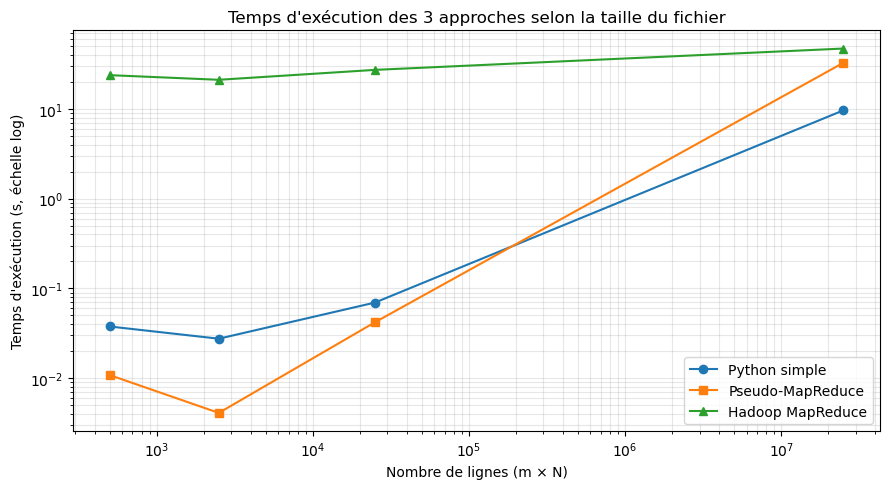

In [13]:
lignes = [m * N for m in M_VALEURS]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(lignes, [temps_v1[m] for m in M_VALEURS], "o-", label="Python simple")
ax.plot(lignes, [temps_v2[m] for m in M_VALEURS], "s-", label="Pseudo-MapReduce")
ax.plot(lignes, [temps_v3[m] for m in M_VALEURS], "^-", label="Hadoop MapReduce")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nombre de lignes (m × N)")
ax.set_ylabel("Temps d'exécution (s, échelle log)")
ax.set_title("Temps d'exécution des 3 approches selon la taille du fichier")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Conclusion

- **Les trois méthodes donnent exactement les mêmes comptages** : seul le temps de calcul change.
- **Python simple** est le plus rapide sur l'ensemble de nos fichiers, son temps croît linéairement avec la taille.
- **Pseudo-MapReduce** est environ 3 fois plus lent sur les gros fichiers, car il crée une paire `(mot, 1)` par mot puis les regroupe. Il montre la logique de MapReduce, mais sans plusieurs machines pour répartir le travail, ces étapes en plus ne font que coûter du temps.
- **Hadoop** prend une vingtaine de secondes même pour 500 lignes : son temps est dominé par un **coût fixe** (démarrage de la JVM, YARN, lecture/écriture HDFS). 

**Bilan :** pour des données qui tiennent sur une machine, Python suffit. Hadoop ne dépasse jamais Python : il part avec ~20 s de retard et son coût par ligne est plus élevé.